In [ ]:
import pandas as pd
from sklearn.naive_bayes import CategoricalNB
from sklearn.preprocessing import LabelEncoder

In [37]:
data = {
    'age' : ['Youth','Youth','Middle','Senior','Senior','Middle','Senior','Youth','Youth','Senior','Youth','Middle','Middle','Senior'],
    'income' : ['High','High','High','Midium','Low','Low','Low','Midium','Low','Midium','Midium','Midium','High','Midium'],
    'student' : ['No','No','No','No','Yes','Yes','Yes','No','Yes','Yes','Yes','No','Yes','No'],
    'credit_rating' : ['Fair','Excellent','Fair','Fair','Fair','Excellent','Excellent','Fair','Fair','Fair','Excellent','Excellent','Fair','Excellent'],
    'buyscomputer' : ['No','No','Yes','Yes','Yes','No','Yes','No','Yes','Yes','Yes','Yes','Yes','No']
}

In [38]:
df = pd.DataFrame(data)

In [39]:
df

,age,income,student,credit_rating,buyscomputer
0,Youth,High,No,Fair,No
1,Youth,High,No,Excellent,No
2,Middle,High,No,Fair,Yes
3,Senior,Midium,No,Fair,Yes
4,Senior,Low,Yes,Fair,Yes
5,Middle,Low,Yes,Excellent,No
6,Senior,Low,Yes,Excellent,Yes
7,Youth,Midium,No,Fair,No
8,Youth,Low,Yes,Fair,Yes
9,Senior,Midium,Yes,Fair,Yes


In [40]:
# Encode categorical --> Numeric

In [41]:
le = {} # create empty dictionary
df_enc = df.copy() # here we just copy our original data
for col in df.columns:
    le[col] = LabelEncoder()
    df_enc[col] = le[col].fit_transform(df[col])

In [42]:
df_enc

,age,income,student,credit_rating,buyscomputer
0,2,0,0,1,0
1,2,0,0,0,0
2,0,0,0,1,1
3,1,2,0,1,1
4,1,1,1,1,1
5,0,1,1,0,0
6,1,1,1,0,1
7,2,2,0,1,0
8,2,1,1,1,1
9,1,2,1,1,1


In [43]:
# features & Target

In [50]:
X = df_enc[['age','income','student','credit_rating']]
Y = df_enc['buyscomputer']

In [51]:
X

,age,income,student,credit_rating
0,2,0,0,1
1,2,0,0,0
2,0,0,0,1
3,1,2,0,1
4,1,1,1,1
5,0,1,1,0
6,1,1,1,0
7,2,2,0,1
8,2,1,1,1
9,1,2,1,1


In [52]:
model = CategoricalNB()
model.fit(X,Y)

CategoricalNB()

In [47]:
test = [['Youth','Midium','Yes','Fair']]

In [48]:
test

[['Youth', 'Midium', 'Yes', 'Fair']]

In [53]:
print("-- Prediction -----------------------")
for t in test:
        row = [[
            le['age'].transform([t[0]])[0],
            le['income'].transform([t[1]])[0],
            le['student'].transform([t[2]])[0],
            le['credit_rating'].transform([t[3]])[0]
        ]]
        pred = le['buyscomputer'].inverse_transform(model.predict(row))[0]
        prob = model.predict_proba(row)[0]
        print(f"Input : age={t[0]}, income={t[1]}, student={t[2]}, credit_rating={t[3]}")
        print(f"Result : Buy Computer -> {pred}")
        print(f"P(No) = {prob[0]:.4f}")
        print(f"P(Yes) = {prob[1]:.4f}")

-- Prediction -----------------------
Input : age=Youth, income=Midium, student=Yes, credit_rating=Fair
Result : Buy Computer -> Yes
P(No) = 0.2322
P(Yes) = 0.7678


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but CategoricalNB was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but CategoricalNB was fitted with feature names
  warnings.warn(


In [54]:
from sklearn.metrics import accuracy_score
y_pred = model.predict(X)
print(f"\nTraining Accuracy : {accuracy_score(y, y_pred)*100:.2f}%")


Training Accuracy : 78.57%


In [60]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but CategoricalNB was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but CategoricalNB was fitted with feature names
  warnings.warn(


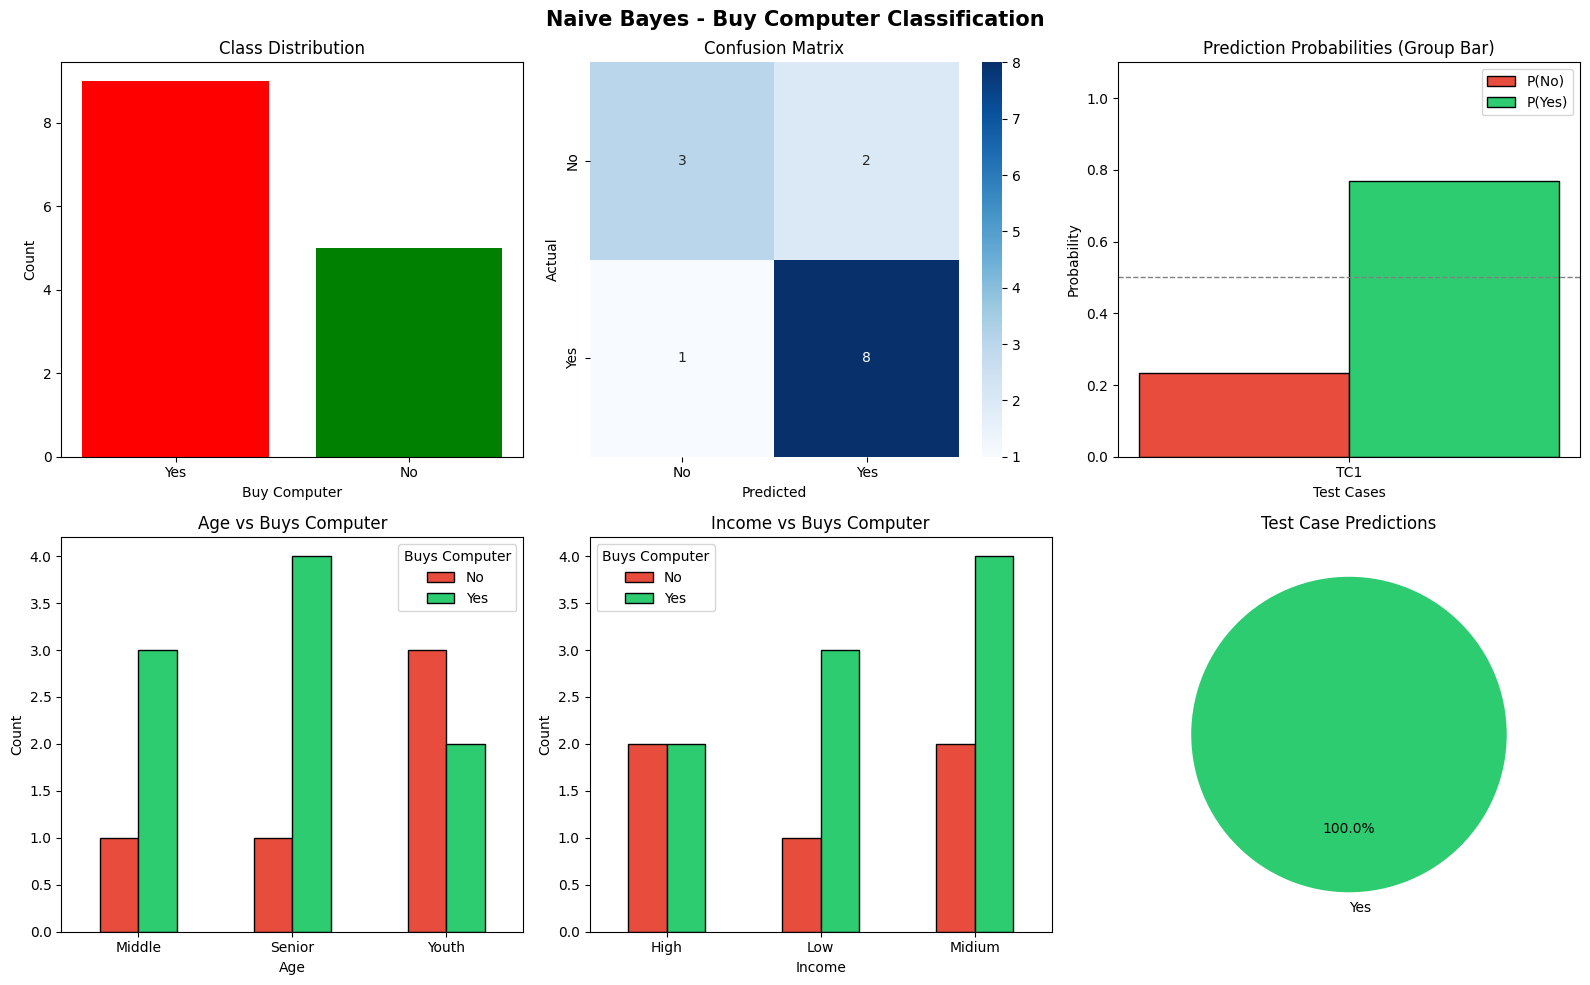

In [69]:
# Pre-calculate variables for the test predictions so the plots work
test_cases = test
probs_no = []
probs_yes = []
predictions = []

for t in test_cases:
    row_data = [[
        le['age'].transform([t[0]])[0],
        le['income'].transform([t[1]])[0],
        le['student'].transform([t[2]])[0],
        le['credit_rating'].transform([t[3]])[0]
    ]]
    prob = model.predict_proba(row_data)[0]
    pred = le['buyscomputer'].inverse_transform(model.predict(row_data))[0]
    probs_no.append(prob[0])
    probs_yes.append(prob[1])
    predictions.append(pred)

# --Plots------
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
fig.suptitle("Naive Bayes - Buy Computer Classification", fontsize=15, fontweight='bold')

# 1. Class Distribution
counts = df['buyscomputer'].value_counts()
axes[0, 0].bar(counts.index, counts.values, color=['red', 'green'])
axes[0, 0].set_title('Class Distribution')
axes[0, 0].set_xlabel('Buy Computer')
axes[0, 0].set_ylabel('Count')

# 2. Confusion Matrix
cm = confusion_matrix(Y, model.predict(X))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=["No", "Yes"], yticklabels=["No", "Yes"], ax=axes[0, 1])
axes[0, 1].set_title('Confusion Matrix')
axes[0, 1].set_xlabel('Predicted')
axes[0, 1].set_ylabel('Actual')

# 3. Prediction Probabilities (Group Bar)
tc_lables = [f"TC{i+1}" for i in range(len(test_cases))]
x_pos = np.arange(len(tc_lables))
w = 0.3
axes[0, 2].bar(x_pos - w/2, probs_no, w, label='P(No)', color='#e74c3c', edgecolor='black')
axes[0, 2].bar(x_pos + w/2, probs_yes, w, label='P(Yes)', color='#2ecc71', edgecolor='black')
axes[0, 2].axhline(0.5, color='gray', linestyle='--', linewidth=1)
axes[0, 2].set_title("Prediction Probabilities (Group Bar)")
axes[0, 2].set_xlabel('Test Cases')
axes[0, 2].set_xticks(x_pos)
axes[0, 2].set_xticklabels(tc_lables)
axes[0, 2].set_ylabel('Probability')
axes[0, 2].set_ylim(0, 1.1)
axes[0, 2].legend()

# 4. Age vs Buys Computer
age_counts = df.groupby(['age', 'buyscomputer']).size().unstack(fill_value=0)
age_counts.plot(kind='bar', ax=axes[1, 0], color=['#e74c3c', '#2ecc71'], edgecolor='black', rot=0)
axes[1, 0].set_title('Age vs Buys Computer')
axes[1, 0].set_xlabel('Age')
axes[1, 0].set_ylabel('Count')
axes[1, 0].legend(title="Buys Computer")

# 5. Income vs Buys Computer
inc_counts = df.groupby(['income', 'buyscomputer']).size().unstack(fill_value=0)
inc_counts.plot(kind='bar', ax=axes[1, 1], color=['#e74c3c', '#2ecc71'], edgecolor='black', rot=0)
axes[1, 1].set_title('Income vs Buys Computer')
axes[1, 1].set_xlabel('Income')
axes[1, 1].set_ylabel('Count')
axes[1, 1].legend(title="Buys Computer")

# 6. Pie Chart - Final Predictions
pred_counts = pd.Series(predictions).value_counts()
colors_pie = ['#2ecc71' if l == 'Yes' else '#e74c3c' for l in pred_counts.index]
axes[1, 2].pie(pred_counts.values, labels=pred_counts.index, colors=colors_pie, autopct='%1.1f%%', startangle=90)
axes[1, 2].set_title('Test Case Predictions')

plt.tight_layout()
plt.show()

In [ ]:
_